<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo" />
</center>

# IV. REGRESSION ANALYSIS AND MACHINE LEARNING PREDICTION

**Bộ dữ liệu:** `data/processed/olist_model_dataset.csv` – 95,824 đơn hàng đã giao, mỗi dòng tương ứng với một `order_id`.

| Cột | Ý nghĩa |
|---|---|
| `order_id` | Mã đơn hàng (không dùng làm biến đầu vào) |
| `delay_days` | Số ngày giao hàng trễ so với ngày giao dự kiến |
| `item_count` | Số dòng sản phẩm trong đơn hàng |
| `low_review` | Biến mục tiêu: 1 nếu `review_score <= 2`, 0 nếu `review_score >= 3` |

**Mục tiêu:** sử dụng `delay_days` và `item_count` để dự đoán khả năng một đơn hàng nhận đánh giá thấp.

## Import Libraries

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

## Load Dataset


In [2]:
BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").is_dir())
df = pd.read_csv(BASE_DIR / "data" / "processed" / "olist_model_dataset.csv")

print(df.shape)
df.head()

(95824, 4)


,order_id,delay_days,item_count,low_review
0,e481f51cbdc54678b7cc49136f2d6af7,-8,1,0
1,53cdb2fc8bc7dce0b6741e2150273451,-6,1,0
2,47770eb9100c2d0c44946d9cf07ec65d,-18,1,0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,1,0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,1,0


## 4.1. Xác định biến đầu vào và biến mục tiêu

### Biến đầu vào – X

- `delay_days`: giá trị dương nghĩa là đơn hàng giao sau ngày dự kiến, giá trị âm nghĩa là giao sớm.
- `item_count`: thước đo đơn giản cho độ phức tạp của đơn hàng.

### Biến mục tiêu – y

`low_review` là biến nhị phân: 0 = đánh giá bình thường hoặc cao, 1 = đánh giá thấp. `order_id` chỉ là mã định danh và `review_score` không được dùng làm biến đầu vào.

Trước khi huấn luyện, cần kiểm tra kiểu dữ liệu, giá trị thiếu, đơn hàng trùng lặp và miền giá trị của hai biến đầu vào.

In [3]:
print(df.dtypes)
print("Missing values:", df.isnull().sum().sum())
print("Duplicated order_id:", df["order_id"].duplicated().sum())
print(df[["delay_days", "item_count", "low_review"]].agg(["min", "max", "median"]))

order_id        str
delay_days    int64
item_count    int64
low_review    int64
dtype: object
Missing values: 0
Duplicated order_id: 0
        delay_days  item_count  low_review
min         -147.0         1.0         0.0
max          188.0        21.0         1.0
median       -12.0         1.0         0.0


In [4]:
X = df[["delay_days", "item_count"]]
y = df["low_review"]

print("X:", X.shape)
print("y:", y.shape)

X: (95824, 2)
y: (95824,)


In [5]:
counts = y.value_counts().sort_index()
percent = (counts / len(y) * 100).round(2)

print(pd.DataFrame({"Orders": counts, "Percent": percent}))

            Orders  Percent
low_review                 
0            83556     87.2
1            12268     12.8


**Nhận xét:** biến mục tiêu bị mất cân bằng – chỉ 12,268 đơn hàng (12.80%) là đánh giá thấp, so với 83,556 đơn hàng (87.20%), tỷ lệ khoảng 6.8 : 1. Một mô hình luôn dự đoán lớp 0 đã đạt 87.20% Accuracy, nên không thể chỉ dùng Accuracy để đánh giá hai mô hình. Các giá trị `delay_days` âm là đơn hàng giao sớm và vẫn được giữ lại vì đây là trường hợp hợp lệ.

## 4.2. Chia tập Train và Test

80% số đơn hàng dùng để huấn luyện và 20% để kiểm tra. `stratify=y` giữ nguyên tỷ lệ lớp 87.20% / 12.80% ở cả hai tập, nên tập Test phản ánh đúng phân bố lớp thực tế và việc so sánh hai mô hình là công bằng.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (76659, 2) | X_test: (19165, 2)
y_train: (76659,) | y_test: (19165,)


In [8]:
split_table = pd.DataFrame([
    {
        "Split": name,
        "Orders": len(part),
        "Class 0 (%)": round((part == 0).mean() * 100, 2),
        "Class 1 (%)": round((part == 1).mean() * 100, 2),
    }
    for name, part in [("Overall", y), ("Training", y_train), ("Testing", y_test)]
])

split_table

,Split,Orders,Class 0 (%),Class 1 (%)
0,Overall,95824,87.2,12.8
1,Training,76659,87.2,12.8
2,Testing,19165,87.2,12.8


**Nhận xét:** tỷ lệ lớp giống hệt nhau (87.20% / 12.80%) ở toàn bộ dữ liệu, tập Train (76,659 đơn) và tập Test (19,165 đơn, trong đó có 2,454 đánh giá thấp), nên việc chia có phân tầng đã hoạt động đúng như mong đợi.

## 4.3. Lựa chọn mô hình

Hai mô hình được so sánh: Logistic Regression làm mô hình cơ sở và Random Forest làm mô hình chính. Mọi bước học tham số từ dữ liệu (kể cả chuẩn hóa) chỉ được fit trên `X_train`; tập Test chỉ dùng để đánh giá.

### 4.3.1. Mô hình 1 – Logistic Regression (mô hình cơ sở)

Logistic Regression ước lượng xác suất một đơn hàng thuộc lớp 1 bằng tổ hợp tuyến tính của các biến đầu vào. Đây là mô hình cơ sở tự nhiên cho bài toán phân loại nhị phân và giúp dễ hiểu tác động của từng biến. Hai biến được chuẩn hóa bằng `StandardScaler` đặt trong `Pipeline`, nên scaler chỉ được fit trên tập Train.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42)),
])

log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

print(f"Train accuracy: {log_reg.score(X_train, y_train):.4f}")
print(f"Test accuracy : {log_reg.score(X_test, y_test):.4f}")

Train accuracy: 0.8777
Test accuracy : 0.8774


### 4.3.2. Mô hình 2 – Random Forest Classifier (mô hình chính)

Random Forest lấy trung bình nhiều cây quyết định nên có thể học các quan hệ phi tuyến và tương tác giữa `delay_days` và `item_count`. Mô hình không cần chuẩn hóa dữ liệu. `class_weight="balanced"` tăng trọng số cho lớp thiểu số (đánh giá thấp) trong quá trình huấn luyện.

In [10]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced"
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)
y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

print(f"Train accuracy: {random_forest.score(X_train, y_train):.4f}")
print(f"Test accuracy : {random_forest.score(X_test, y_test):.4f}")

Train accuracy: 0.8419
Test accuracy : 0.8395


## 4.4. Đánh giá mô hình

Do dữ liệu mất cân bằng, năm chỉ số được tính trên cùng một tập Test:

| Chỉ số | Ý nghĩa |
|---|---|
| Accuracy | Tỷ lệ đơn hàng được phân loại đúng trên toàn bộ |
| Precision (lớp 1) | Trong số đơn được dự đoán là đánh giá thấp, bao nhiêu đơn thực sự đúng |
| Recall (lớp 1) | Trong số đơn thực sự đánh giá thấp, mô hình phát hiện được bao nhiêu |
| Macro-F1 | F1 trung bình của hai lớp, nên lớp 1 có trọng số ngang với lớp 0 |
| PR-AUC | Diện tích dưới đường precision–recall của xác suất dự đoán lớp 1 |

### A. Các chỉ số đánh giá

Precision và Recall được tính cho lớp 1 (`pos_label=1`). PR-AUC dùng xác suất dự đoán lớp 1, không dùng nhãn dự đoán 0/1. Bảng kết quả bên dưới đồng thời là bảng so sánh hai mô hình.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
)

predictions = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Random Forest": (y_pred_rf, y_prob_rf),
}

metrics_table = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=1),
        "Recall": recall_score(y_test, pred, pos_label=1),
        "Macro-F1": f1_score(y_test, pred, average="macro"),
        "PR-AUC": average_precision_score(y_test, prob),
    }
    for name, (pred, prob) in predictions.items()
]).round(4)

metrics_table

,Model,Accuracy,Precision,Recall,Macro-F1,PR-AUC
0,Logistic Regression,0.8774,0.6636,0.0868,0.5437,0.3756
1,Random Forest,0.8395,0.3992,0.5020,0.6755,0.4317


### B. Ma trận nhầm lẫn – Logistic Regression

Ma trận thể hiện True Negative (góc trên trái), False Positive (góc trên phải), False Negative (góc dưới trái) và True Positive (góc dưới phải). False Negative là các đơn thực sự đánh giá thấp mà mô hình bỏ sót, đây là loại sai số tốn kém nhất trong bài toán này.

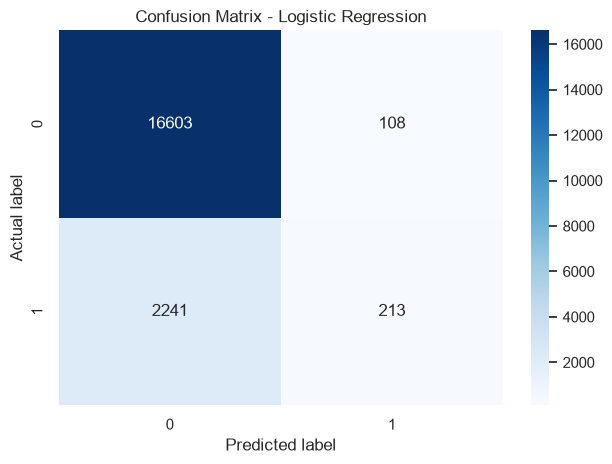

In [12]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=["0", "1"], yticklabels=["0", "1"])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

### C. Ma trận nhầm lẫn – Random Forest

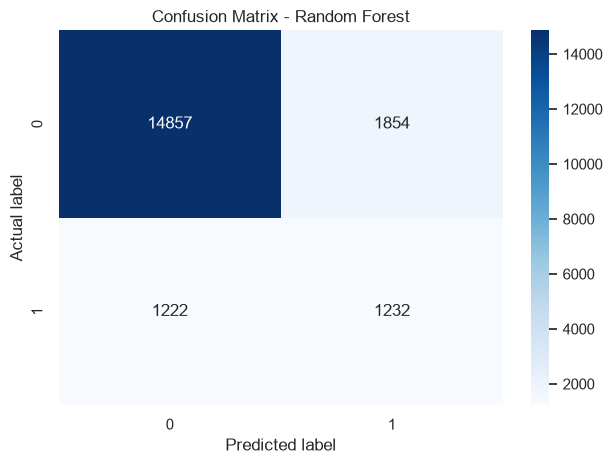

In [13]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues",
            xticklabels=["0", "1"], yticklabels=["0", "1"])
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

**Đọc ma trận:**
- Logistic Regression: 16,603 True Negative, 108 False Positive, 2,241 False Negative, 213 True Positive.
- Random Forest: 14,857 True Negative, 1,854 False Positive, 1,222 False Negative, 1,232 True Positive.

Random Forest bỏ sót 1,222 trên 2,454 đơn đánh giá thấp, còn Logistic Regression bỏ sót 2,241 đơn – khoảng 1.8 lần nhiều hơn.

### D. Nhận xét

- **Accuracy:** Logistic Regression cao hơn (0.8774 so với 0.8395), nhưng chỉ đạt được nhờ dự đoán lớp 1 cho 321 đơn: mức 87.20% có thể đạt được bằng cách không bao giờ dự đoán đánh giá thấp.
- **Macro-F1:** Random Forest tốt hơn rõ rệt (0.6755 so với 0.5437), vì F1 của lớp 1 ở mô hình cơ sở rất thấp.
- **Recall (lớp 1):** Random Forest phát hiện 50.20% đánh giá thấp (1,232/2,454), Logistic Regression chỉ phát hiện 8.68% (213/2,454).
- **PR-AUC:** Random Forest cao hơn (0.4317 so với 0.3756). Cả hai đều cao hơn mức tham chiếu 0.128 (tỷ lệ lớp 1 trong tập Test), nhưng chưa cao về giá trị tuyệt đối.
- **Đánh đổi Precision/Recall:** Random Forest tăng Recall từ 0.0868 lên 0.5020 nhưng giảm Precision (0.6636 xuống 0.3992) và tạo ra 1,854 False Positive; Logistic Regression thận trọng hơn với 108 False Positive nhưng bỏ sót gần như toàn bộ đánh giá thấp. Một phần khoảng cách này đến từ `class_weight="balanced"` ở Random Forest, trong khi mô hình cơ sở không dùng thiết lập này.

Dựa trên Macro-F1, Recall của lớp 1 và PR-AUC, Random Forest cho kết quả tốt hơn trên tập Test dù Accuracy thấp hơn.

## 4.5. Tầm quan trọng của biến & Kết luận

### 4.5.1. Permutation Feature Importance

Permutation Importance lần lượt xáo trộn từng biến trong `X_test` và đo mức giảm của Macro-F1. Vì Random Forest có Macro-F1 cao hơn, mô hình này được dùng cho phân tích: mô hình được chọn theo Macro-F1 thực tế chứ không cố định.

In [14]:
from sklearn.inspection import permutation_importance

best_name = metrics_table.loc[metrics_table["Macro-F1"].idxmax(), "Model"]
fitted_models = {"Logistic Regression": log_reg, "Random Forest": random_forest}
best_model = fitted_models[best_name]
print("Model used for importance analysis:", best_name)

perm = permutation_importance(
    best_model, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=42
)

importance_table = pd.DataFrame({
    "Feature": X.columns,
    "Mean Importance": perm.importances_mean,
    "Standard Deviation": perm.importances_std,
}).round(4)

importance_table

Model used for importance analysis: Random Forest


,Feature,Mean Importance,Standard Deviation
0,delay_days,0.1262,0.0019
1,item_count,0.0557,0.0037


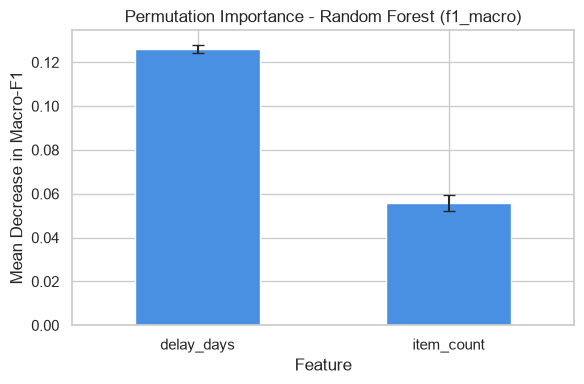

In [15]:
ax = importance_table.plot(
    kind="bar", x="Feature", y="Mean Importance", yerr="Standard Deviation",
    color="#4A90E2", legend=False, figsize=(6, 4), capsize=4,
)
plt.title(f"Permutation Importance - Random Forest (f1_macro)")
plt.xlabel("Feature")
plt.ylabel("Mean Decrease in Macro-F1")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Nhận xét:** xáo trộn `delay_days` làm Macro-F1 giảm trung bình 0.1262 (độ lệch chuẩn 0.0019), còn xáo trộn `item_count` làm giảm 0.0557 (độ lệch chuẩn 0.0037). Cả hai giá trị đều dương và khoảng sai số không chồng lên nhau, nên `delay_days` quan trọng hơn khoảng 2.3 lần so với `item_count`, nhưng `item_count` vẫn mang thông tin riêng. Chỉ số này phản ánh mức đóng góp cho mô hình và chỉ số đang dùng, không chứng minh quan hệ nhân quả.

### 4.5.2. Kết luận

1. **Mô hình nào dự đoán tốt hơn?** Random Forest tốt hơn trên tập Test: Macro-F1 0.6755 so với 0.5437, Recall lớp 1 0.5020 so với 0.0868 và PR-AUC 0.4317 so với 0.3756. Logistic Regression chỉ cao hơn ở Accuracy (0.8774 so với 0.8395), và chỉ số này gây hiểu nhầm với dữ liệu mất cân bằng.
2. **Khả năng phát hiện đơn đánh giá thấp tốt đến mức nào?** Random Forest phát hiện được khoảng một nửa số đơn đánh giá thấp (1,232 trên 2,454) với Precision 0.3992, nghĩa là khoảng 6/10 đơn bị gắn cờ không thực sự là đánh giá thấp. Kết quả này dùng được như một tín hiệu cảnh báo nhưng chưa đủ chính xác để tự động ra quyết định.
3. **Biến nào quan trọng hơn?** `delay_days` quan trọng hơn rõ rệt (Mean Importance 0.1262 so với 0.0557). Điều này khớp với phần III, khi nhóm đơn giao trễ có tỷ lệ đánh giá thấp cao hơn nhiều so với nhóm đơn đúng giờ.
4. **Hai biến đầu vào có đủ để dự đoán chính xác?** Không. Với chỉ `delay_days` và `item_count`, mô hình tốt nhất vẫn bỏ sót khoảng một nửa số đánh giá thấp. Hai biến này giải thích một phần, không phải toàn bộ câu chuyện.

**Hạn chế:**
- Mô hình chỉ dùng hai biến đầu vào nên không có các thông tin khác của đơn hàng.
- Đánh giá của khách hàng còn chịu ảnh hưởng của chất lượng sản phẩm, giá cả, người bán, trải nghiệm vận chuyển và dịch vụ khách hàng, nằm ngoài phạm vi hiện tại.
- Kết quả chỉ là quan hệ thống kê học từ dữ liệu lịch sử, không chứng minh quan hệ nhân quả.
- Mất cân bằng lớp (12.80% đánh giá thấp) làm giới hạn hiệu suất, đặc biệt là Precision của lớp dương.
- Hai mô hình dùng siêu tham số mặc định và mô hình cơ sở không dùng trọng số lớp; nếu tinh chỉnh thêm thì kết quả so sánh có thể thay đổi.